# ND-2 indikatorių programavimas

## Setup'as

In [1]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

## Data

In [2]:
def load_csv(path):
    df = pd.read_csv(path, sep='\t')
    df = df.rename(columns={
        "<DATE>": "date",
        "<OPEN>": "open",
        "<HIGH>": "high",
        "<LOW>": "low",
        "<CLOSE>": "close",
        "<TICKVOL>": "volume",
    })
    df["date"] = pd.to_datetime(df["date"], format="%Y.%m.%d")
    df = df.set_index("date")
    return df[["open", "high", "low", "close", "volume"]]

In [3]:
def load_yf(ticker, start="2023-01-01"):
    # pradedam nuo 2023, kad 2024 pradzioje CMO jau turetu 9 dienu istorija
    df = yf.Ticker(ticker).history(start=start, auto_adjust=False)
    df = df.rename(columns={
        "Open": "open", "High": "high", "Low": "low", "Close": "close", "Volume": "volume",
    })
    df.index = df.index.tz_localize(None)
    return df[["open", "high", "low", "close", "volume"]]


In [4]:
eur = load_csv("data/EURUSD.csv")
eur.head()
eur.tail()

,open,high,low,close,volume
date,,,,,
2025-12-24,1.17903,1.18076,1.17724,1.17772,22307
2025-12-26,1.17784,1.17965,1.17613,1.17709,25441
2025-12-29,1.17615,1.17887,1.17493,1.17721,28134
2025-12-30,1.17665,1.17794,1.17431,1.17475,22789
2025-12-31,1.17437,1.17591,1.17198,1.17456,24633


## Indikatoriu funkcijos

### Exponential moving average


In [5]:
def ema(prices, n):
    alpha = 2 / (n + 1)
    values = prices.to_numpy(dtype=float)
    result = np.empty(len(values))

    result[0] = values[0]
    for i in range(1, len(values)):
        result[i] = alpha * values[i] + (1 - alpha) * result[i -1]

    return pd.Series(result, index=prices.index)

In [6]:
my_ema = ema(eur["close"], 13)
print(my_ema)

date
2024-01-02    1.094090
2024-01-03    1.093806
2024-01-04    1.093899
2024-01-05    1.093918
2024-01-08    1.094064
                ...   
2025-12-24    1.172656
2025-12-26    1.173289
2025-12-29    1.173850
2025-12-30    1.173978
2025-12-31    1.174061
Length: 521, dtype: float64


### Elder Ray

In [7]:
def elder_ray(high, low, close, n=13):
    my_ema = ema(close, n)
    bull = high - my_ema
    bear = low - my_ema
    return bull, bear

### Elder force

In [8]:
def elder_force(close, volume, n=13):
    my_ema = ema(close, n)
    force = my_ema.diff() * volume
    return force

### Chande Momentum Oscillator

In [9]:
def chande_momentum(close, n=9):
    change = close.diff()
    ups = change.clip(lower=0)
    downs = change.clip(upper=0).abs()

    sum_ups = ups.rolling(n).sum()
    sum_downs = downs.rolling(n).sum()

    return 100 * (sum_ups - sum_downs) / (sum_ups + sum_downs)

## Atvaizdavimas

### Elder Ray


In [10]:
def plot_elder_ray(df, bull, bear, title, start=None, end=None, bull_ylim=None, bear_ylim=None):
    df = df.loc[start:end]
    bull = bull.loc[start:end]
    bear = bear.loc[start:end]

    fig, axis = plt.subplots(3, 1, figsize=(14, 9), sharex=True)

    axis[0].plot(df.index, df["close"])
    axis[0].set_title(title)

    axis[1].bar(bull.index, bull, color="green")
    axis[1].axhline(0, color="black", linewidth=0.7)
    axis[1].set_title("Bulls Power (13)")
    if bull_ylim is not None:
        axis[1].set_ylim(bull_ylim)

    axis[2].bar(bear.index, bear, color="red")
    axis[2].axhline(0, color="black", linewidth=0.7)
    axis[2].set_title("Bears Power (13)")
    if bear_ylim is not None:
        axis[2].set_ylim(bear_ylim)

    plt.tight_layout()
    plt.show()


### Elder force

In [11]:
def plot_elder_force(df, force, title, start=None, end=None, force_ylim=None):
    df = df.loc[start:end]
    force = force.loc[start:end]

    fig, axis = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

    axis[0].plot(df.index, df["close"])
    axis[0].set_title(title)

    axis[1].plot(force.index, force, color="purple")
    axis[1].axhline(0, color="black", linewidth=0.7)
    axis[1].set_title("Force Index (13)")
    if force_ylim is not None:
        axis[1].set_ylim(force_ylim)

    plt.tight_layout()
    plt.show()


### Chande Momentum Oscillator

In [12]:
def plot_cmo(df, cmo_values, title, n=9, start=None, end=None):
    df = df.loc[start:end]
    cmo_values = cmo_values.loc[start:end]

    fig, axis = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

    axis[0].plot(df.index, df["close"])
    axis[0].set_title(title)

    axis[1].plot(cmo_values.index, cmo_values, color="green")
    axis[1].axhline(50, color="red", linewidth=0.7, linestyle="--")
    axis[1].axhline(0, color="white", linewidth=0.7)
    axis[1].axhline(-50, color="blue", linewidth=0.7, linestyle="--")
    # tokia pati skale kaip TradingView: -100..100, padalos kas 40
    axis[1].set_ylim(-100, 100)
    axis[1].set_yticks([-80, -40, 0, 40, 80])
    axis[1].set_title(f"Chande Momentum Oscillator ({n})")

    plt.tight_layout()
    plt.show()


# Indikatorių palyginimas

## Indikatoriai Elder Ray index ir Elder Force index EURUSD su screenshot palyginimas
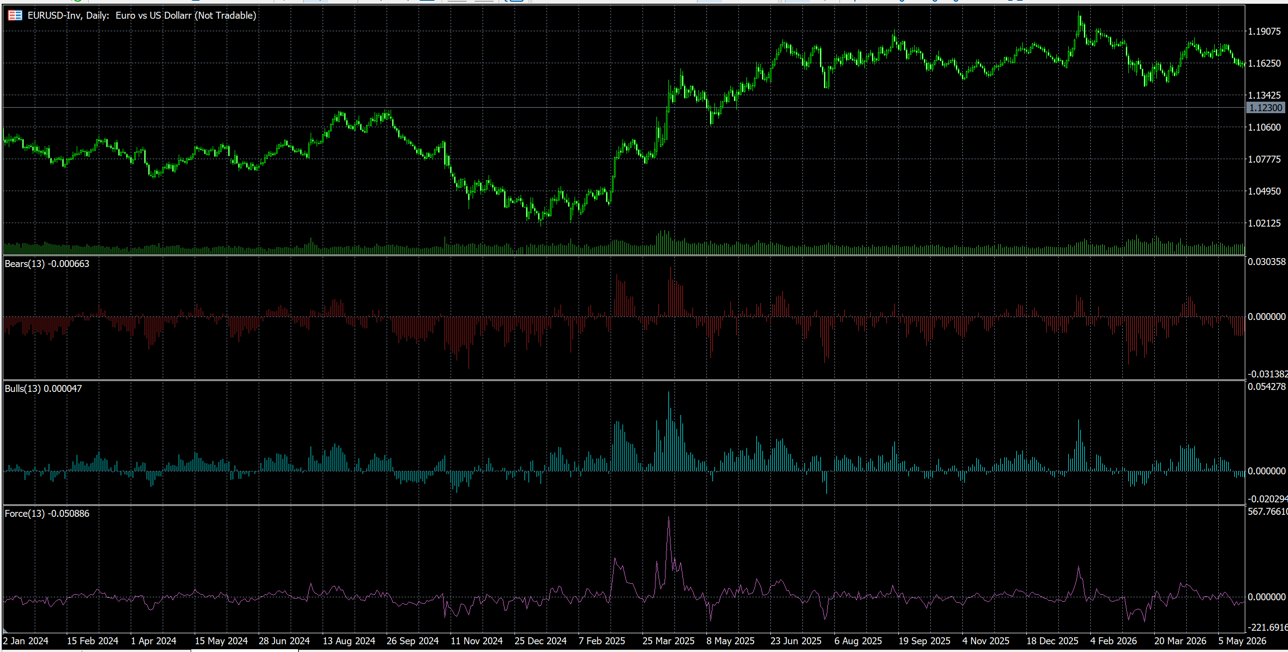

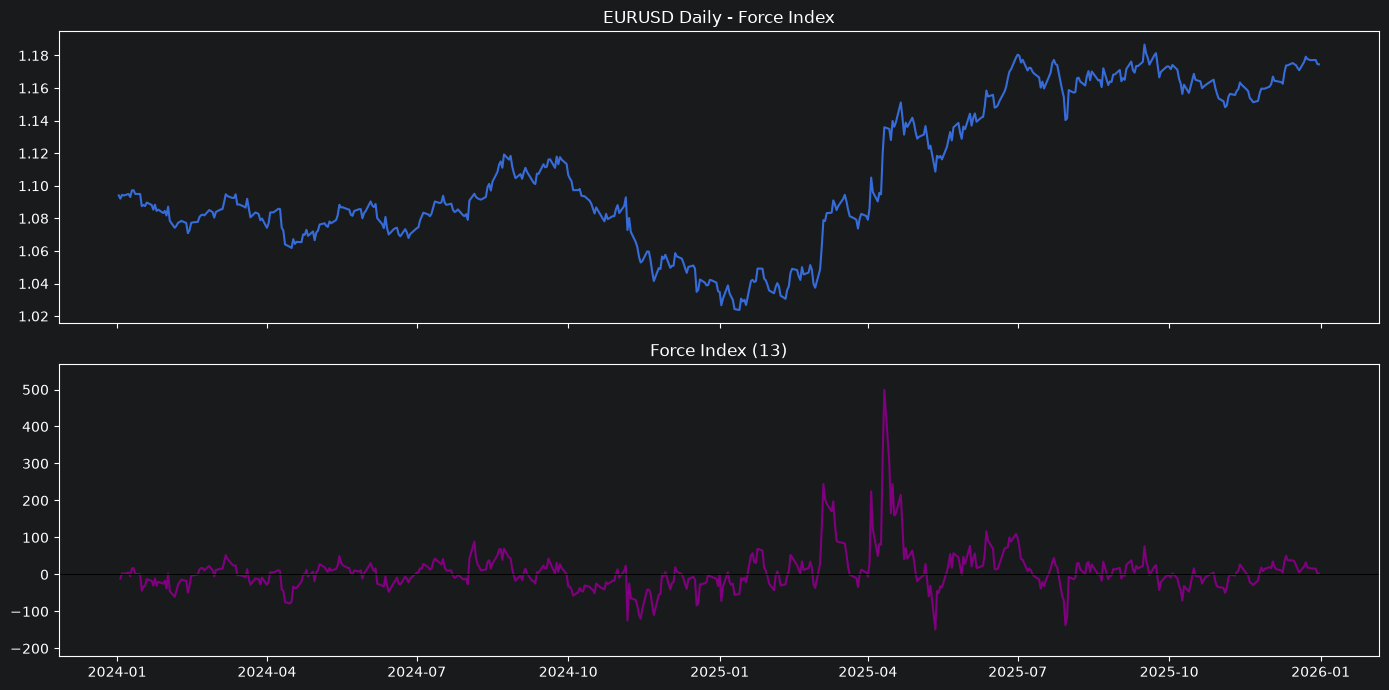

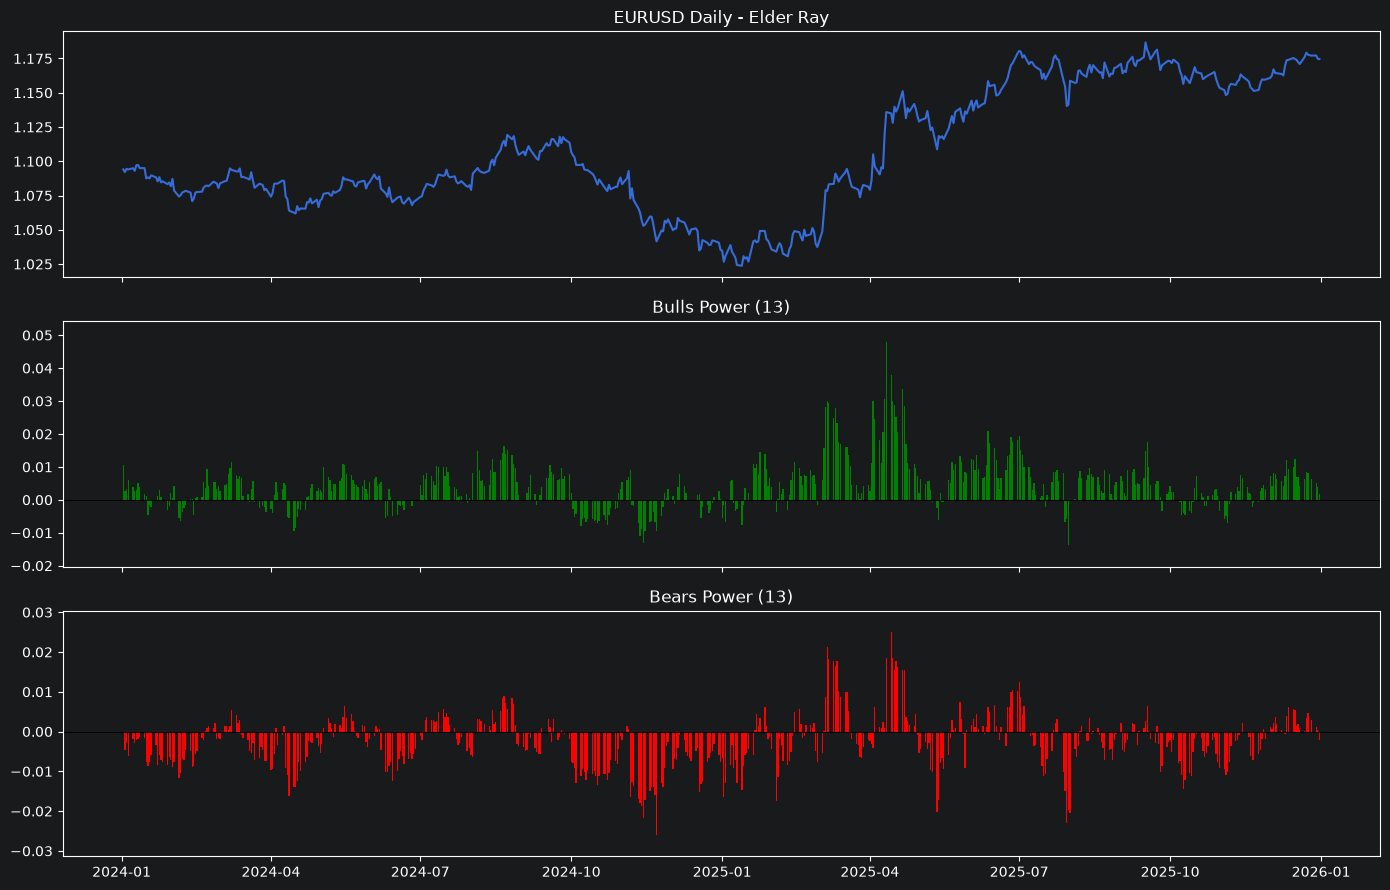

In [13]:
eur = load_csv("data/EURUSD.csv")

eur_force = elder_force(eur["close"], eur["volume"], 13)
plot_elder_force(eur, eur_force, "EURUSD Daily - Force Index", force_ylim=(-221.69, 567.77))

eur_bull, eur_bear = elder_ray(eur["high"], eur["low"], eur["close"], 13)
plot_elder_ray(eur, eur_bull, eur_bear, "EURUSD Daily - Elder Ray",
               bull_ylim=(-0.020294, 0.054278), bear_ylim=(-0.031382, 0.030358))


In [14]:
eur_check = pd.DataFrame({"close": eur["close"], "bulls": eur_bull, "bears": eur_bear, "force": eur_force})
eur_check.loc[["2025-04-11", "2025-06-02", "2025-12-31"]].round(6)


,close,bulls,bears,force
date,,,,
2025-04-11,1.13593,0.047807,0.018467,499.259441
2025-06-02,1.14427,0.012260,0.001540,77.148924
2025-12-31,1.17456,0.001849,-0.002081,2.047419


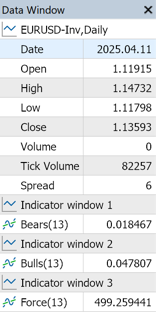

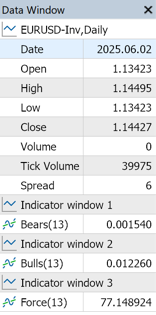

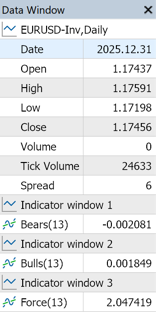

## Indikatoriu Elder Ray index ir Elder Force index GBPUSD su screenshot palyginimimas
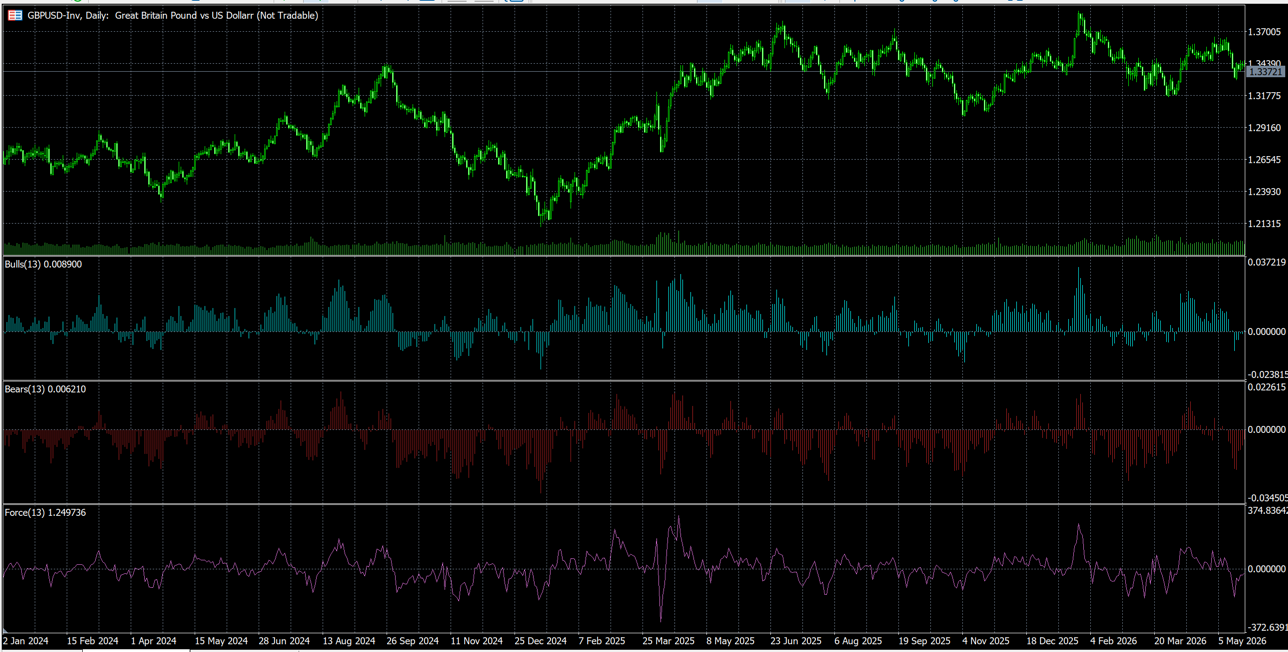

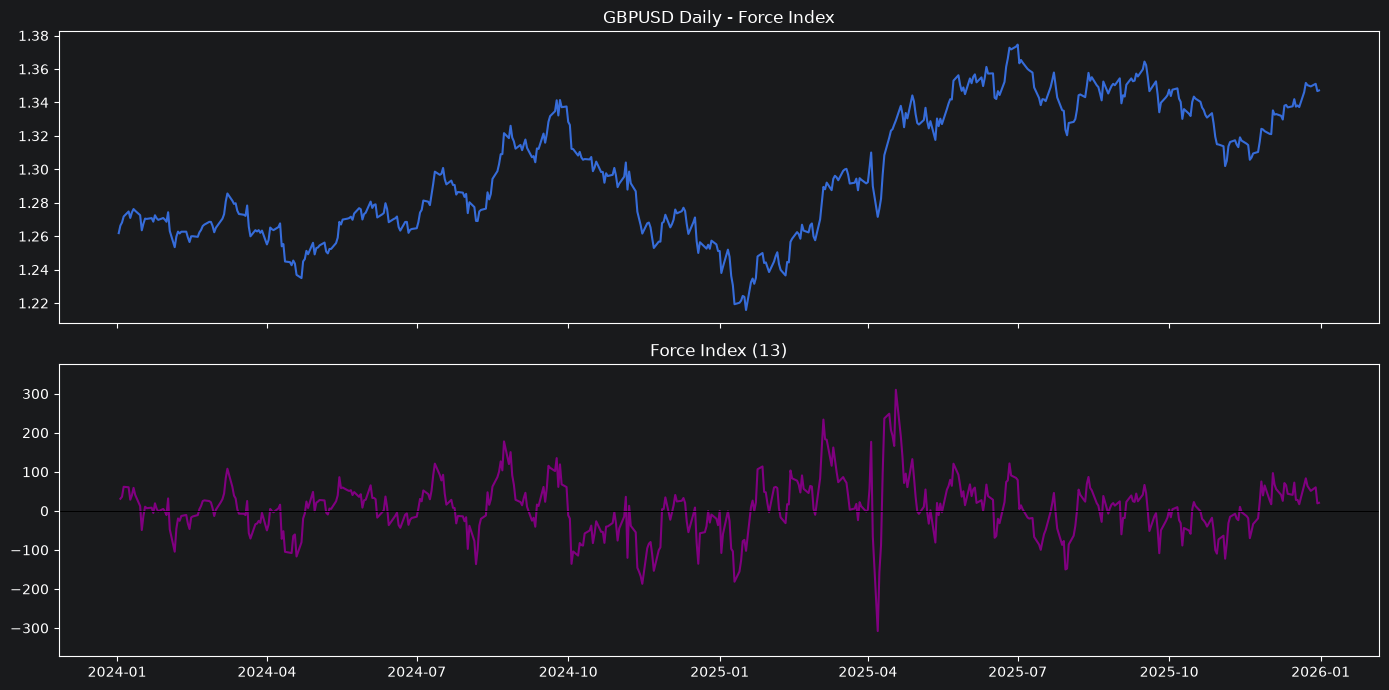

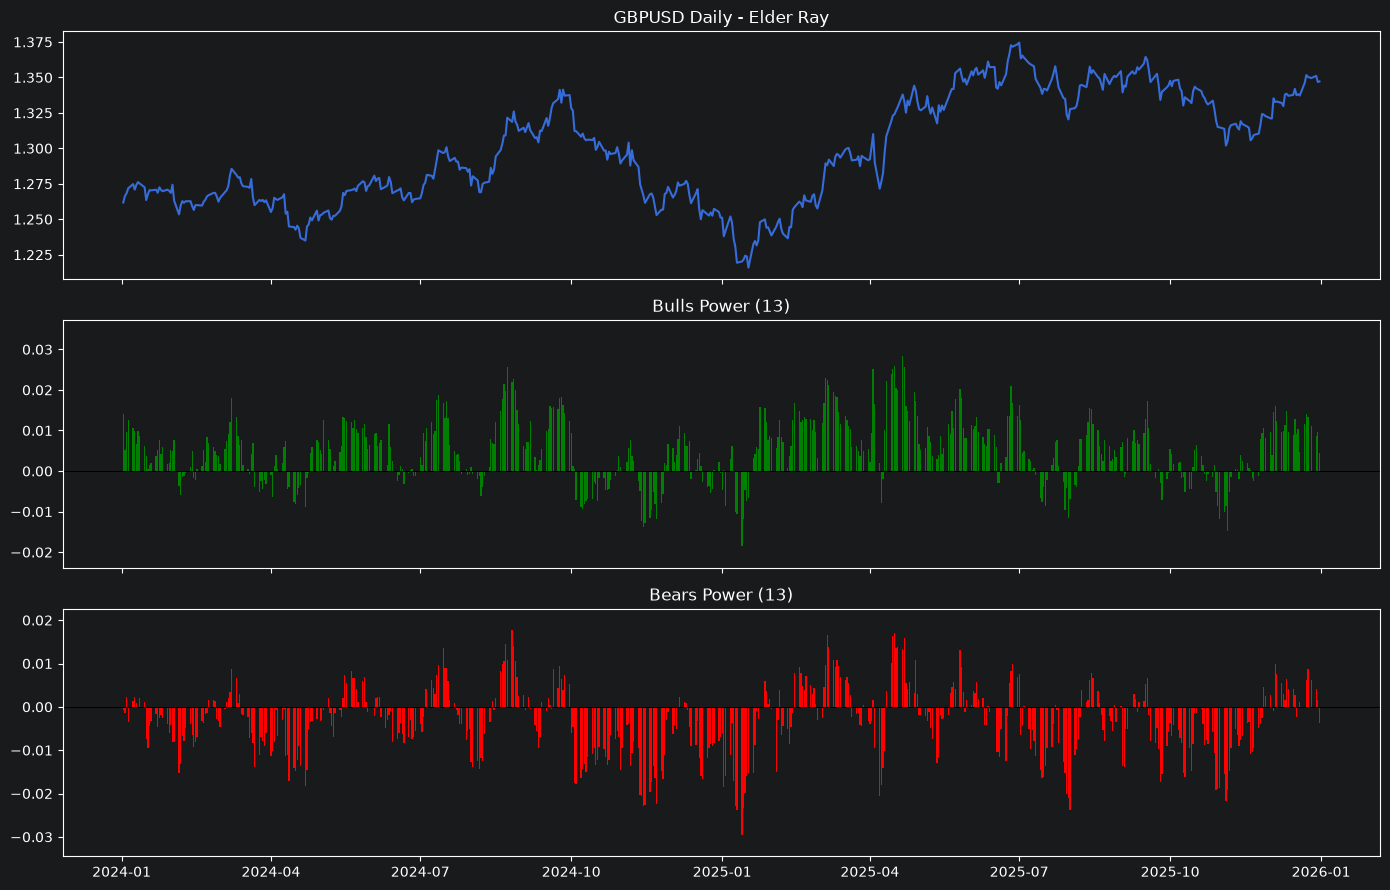

In [15]:
gbp = load_csv("data/GBPUSD.csv")

gbp_force = elder_force(gbp["close"], gbp["volume"], 13)
plot_elder_force(gbp, gbp_force, "GBPUSD Daily - Force Index", force_ylim=(-372.64, 374.84))

gbp_bull, gbp_bear = elder_ray(gbp["high"], gbp["low"], gbp["close"], 13)
plot_elder_ray(gbp, gbp_bull, gbp_bear, "GBPUSD Daily - Elder Ray",
               bull_ylim=(-0.023815, 0.037219), bear_ylim=(-0.034505, 0.022615))


In [16]:
gbp_check = pd.DataFrame({"close": gbp["close"], "bulls": gbp_bull, "bears": gbp_bear, "force": gbp_force})

gbp_check.loc[["2025-04-11", "2025-06-02", "2025-12-31"]].round(6)

,close,bulls,bears,force
date,,,,
2025-04-11,1.30846,0.022219,0.003729,236.638133
2025-06-02,1.35434,0.011333,0.000473,67.874311
2025-12-31,1.34717,0.004372,-0.003798,20.604805


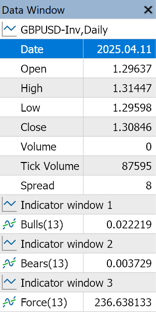

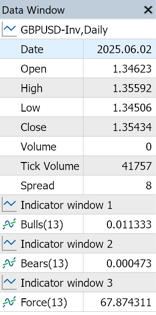

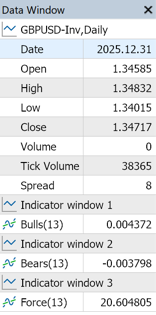
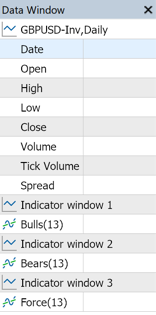

## Chande Momentum Oscillator indikatoriaus palyginimas su dieninėm akcijom (screenshot iš tradingview.com)


### Apple

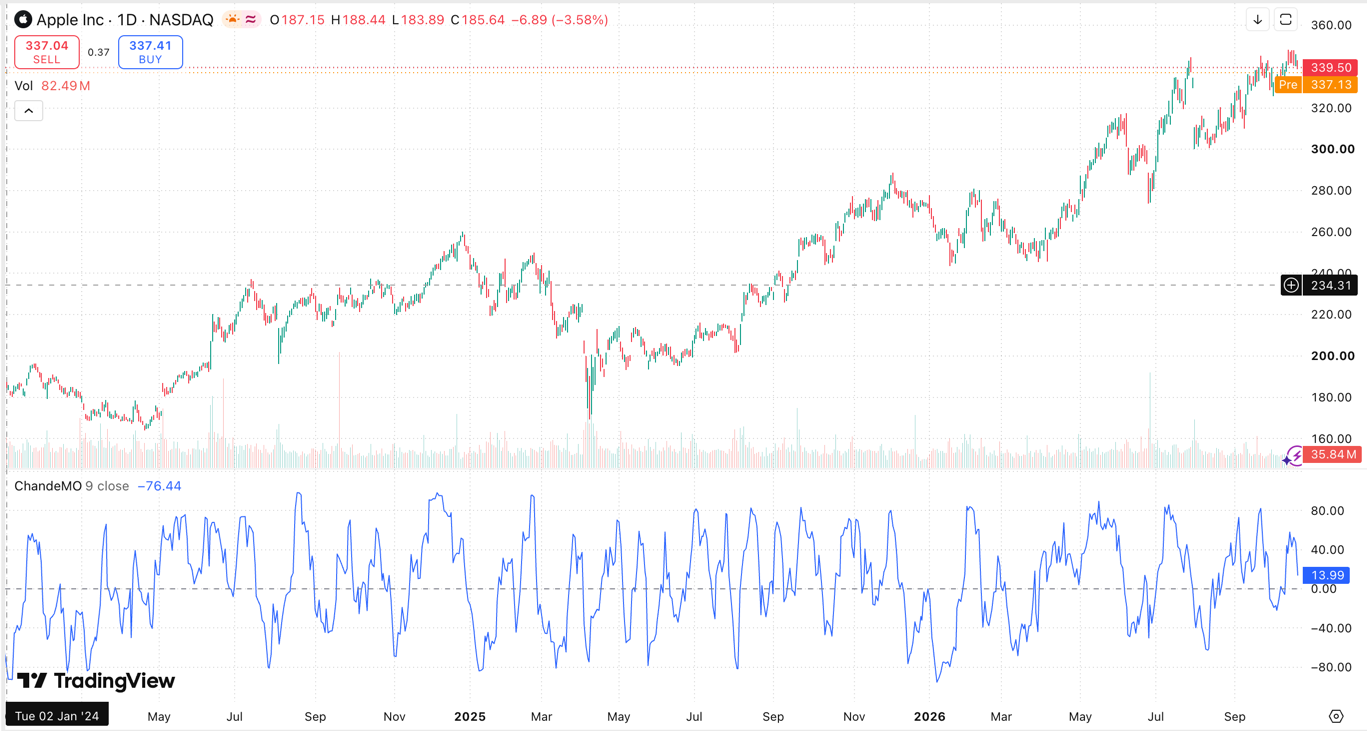

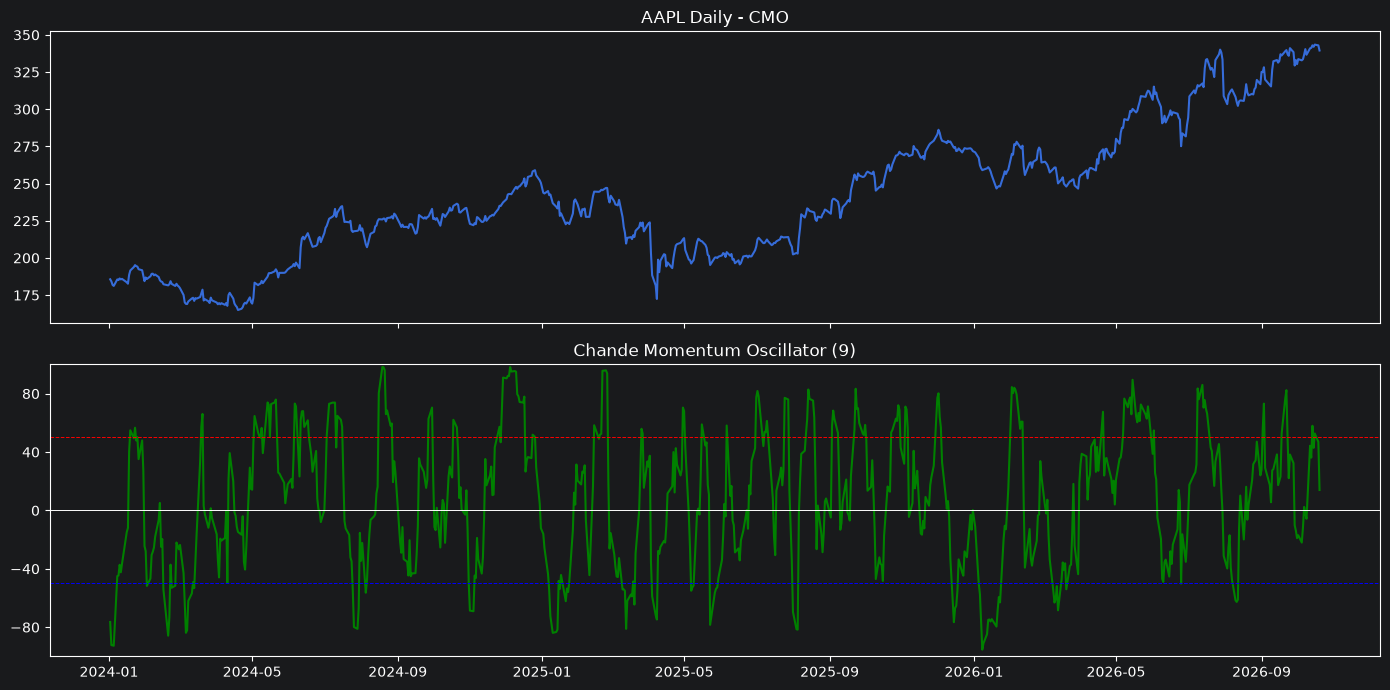

In [17]:
aapl = load_yf("AAPL")
aapl_cmo = chande_momentum(aapl["close"], 9)
plot_cmo(aapl, aapl_cmo, "AAPL Daily - CMO", start="2024-01-01")

In [18]:
aapl_check = pd.DataFrame({"close": aapl["close"], "CMO": aapl_cmo})
aapl_check.loc["2024-01-02"].round(2)

close    185.64
CMO      -76.44
Name: 2024-01-02 00:00:00, dtype: float64

### Nvidia

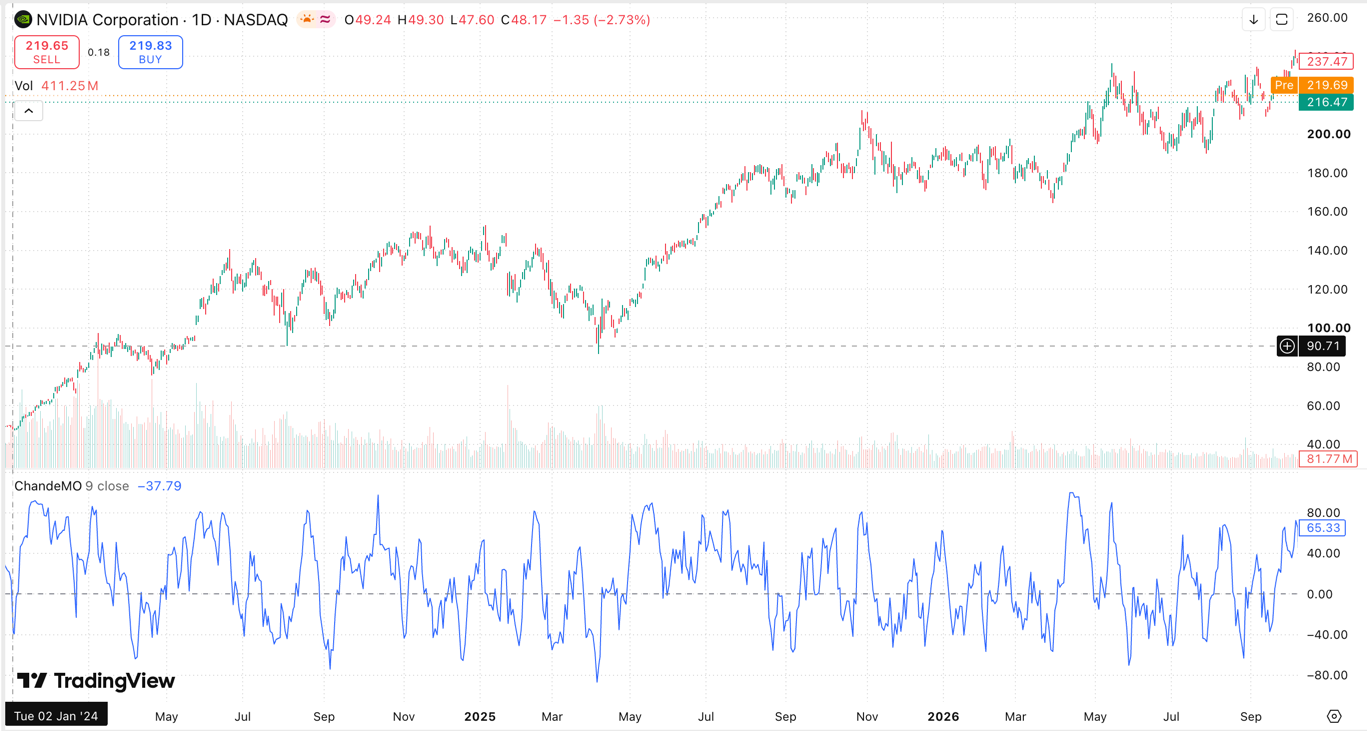

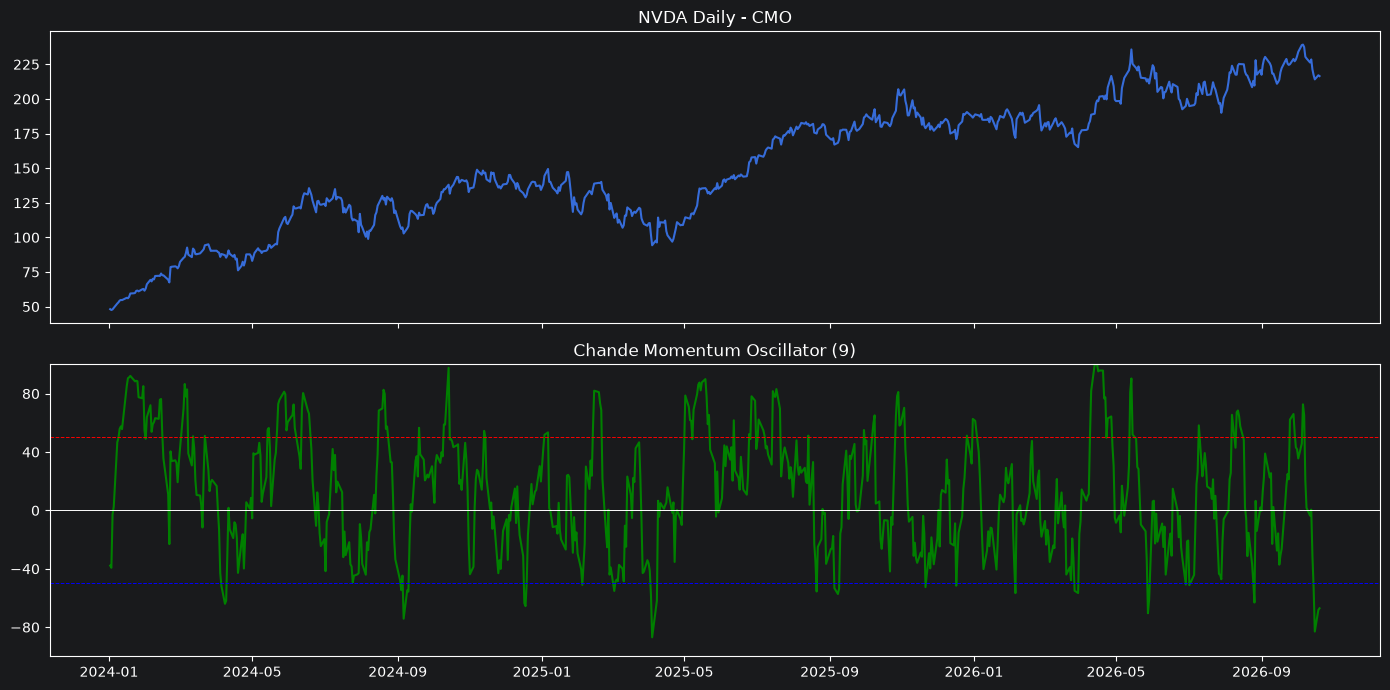

In [19]:
nvda = load_yf("NVDA")
nvda_cmo = chande_momentum(nvda["close"], 9)
plot_cmo(nvda, nvda_cmo, "NVDA Daily - CMO", start="2024-01-01")

In [20]:
nvda_check = pd.DataFrame({"close": nvda["close"], "CMO": nvda_cmo})
nvda_check.loc["2024-01-02"].round(2)

close    48.17
CMO     -37.79
Name: 2024-01-02 00:00:00, dtype: float64